# Telco churn: a GAM (splines + logistic regression), tuned by cross-validation, and the exact shape of each effect

XGBoost (`03_xgboost`) beats the logistic regression by 0.055 ROC-AUC, and its SHAP dependence plots show why: a step in handset age, a peak in tenure, curves in usage. Two questions are still open:
1. **How much of that gain is the shapes, and how much is interactions between variables?** A generalised additive model (GAM) learns one free curve per variable and adds them up, with no interactions. Logistic → GAM measures the shapes; GAM → XGBoost measures the interactions.
2. **Are the SHAP curves real?** In a GAM each variable's curve *is* the model: it is global and exact, one number per value, not an average of scattered points. If it agrees with XGBoost's SHAP, the insight does not depend on the model.

Section 9 then adds three interaction surfaces, to see where one variable's curve depends on another.

Rules (the same as the other model notebooks):
- **Every choice is made on the training set with 5-fold stratified CV**, on the same folds: the number of knots, the penalty, ratios or not.
- **The pipeline model stays XGBoost** (chosen on CV in `03_xgboost`), unless the GAM comes within one paired SE of it in CV (section 3). The rule is fixed here, before any result.
- **The hold-out set is scored once**, for the report, after every choice is frozen. Importance and curves are then read on the hold-out customers, as for XGBoost. Nothing is changed after looking at them.
- All preprocessing lives inside the sklearn `Pipeline`, fitted on the rows it is trained on, so the pickle carries it.
- `Customer_ID` and `ethnic` are never features. Apart from the single-customer explanations (no ID, 10 values each), only aggregates are shown.

All the logic lives in `src/churn/` (`model.py`, `plots.py`); this notebook only calls it.

In [1]:
import numpy as np
import pandas as pd
from scipy.special import expit

from churn import eda, model, plots
from churn.config import ROOT, load_config
from churn.data import clean, load_raw, split

cfg = load_config()
m, s, g = cfg["model"], cfg["shap"], cfg["model"]["gam"]
lf, xf = m["logistic_final"], m["xgboost_final"]
TARGET = cfg["target"]
plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

df = clean(load_raw(ROOT / cfg["paths"]["raw_data"]), cfg["cleaning"])
train, test = split(df, TARGET, cfg["test_size"], cfg["seed"])
X, y = model.split_xy(train, cfg)
colors = plots.family_colors(list(cfg["families"]))
print(f"training set: {len(X):,} customers, {X.shape[1]} input variables; "
      f"hold-out: {len(test):,} customers, not used until section 4")


def summary(cv: pd.DataFrame) -> pd.Series:
    return cv.agg(["mean", "sem"]).apply(lambda c: f"{c['mean']:.4f} ± {c['sem']:.4f}")


def gam_pipeline(C: float, n_knots: int, ratios: bool = True):
    return model.build_pipeline(cfg, model.gam(cfg, C), ratios=ratios, n_knots=n_knots)


def xgb_pipeline():
    return model.build_tree_pipeline(cfg, model.xgboost(cfg, xf["max_depth"], xf["n_trees"]))


def logistic_pipeline():
    return model.build_pipeline(cfg, model.elastic_net(cfg, lf["C"], lf["l1_ratio"]))

training set: 80,000 customers, 97 input variables; hold-out: 20,000 customers, not used until section 4


## 1. From logistic regression to GAM: one change
The GAM is the logistic-regression pipeline with **one extra step**: after the signed log and the median, every numeric variable is replaced by a **cubic B-spline basis**, a few "bump" columns whose weighted sum draws a smooth curve. The logistic regression on top learns the weights, so each variable gets its own curve on the log-odds scale, and the curves are added:

  log-odds of churn = intercept + f₁(eqpdays) + f₂(months) + … + (one coefficient per categorical level and missing indicator)

| Choice | Value | Why |
|---|---|---|
| Spline | cubic B-splines (`SplineTransformer`, degree 3) | smooth curves with smooth slopes; each basis column is local, so a change at 300 days does not move the curve at 900 |
| Knots | at **quantiles** of the training values | the same number of customers between two knots, so no piece of a curve rests on a handful of outliers |
| Beyond the training range | curve held **flat** (`extrapolation="constant"`) | a hold-out customer with an extreme value gets the edge of the curve, not an extrapolated cubic |
| Before the splines | `arcsinh` + median, as in the logistic regression | same inputs; quantile knots do not depend on the transform, only the shape between knots does |
| Missing values | median + one indicator per missing block, as before | the indicator carries the effect of being missing; the curve is read on observed values |
| Categoricals | `Missing` level + one-hot, as before | a categorical already gets one free value per level: it is "non-linear" by construction |
| Penalty | ridge (L2) on all columns after `StandardScaler` | it shrinks the spline weights towards a flat curve; a smaller C means smoother, smaller curves |

What it is not: `mgcv` or `pygam` penalise the curvature of each curve, with one smoothing parameter per variable. Here the smoothness comes from **the number of knots** and **one shared C**, both chosen by CV; that keeps the model inside plain sklearn and its pickle. `pygam` was rejected: a new dependency, known breakages with recent scipy, and its smoothing is tuned by its own grid search.

## 2. Tuning by CV: number of knots and penalty
Two knobs, chosen together:
- **Knots: three values**, 5, 10 and 15 (6, 11 and 16 columns per variable). More knots allow sharper features, such as a step or a one-month peak, at the price of more columns to estimate.
- **C: a path of 9 values** from 10⁻⁴ (heavy shrinkage, nearly flat curves) to 1 (almost none), with `LogisticRegressionCV`, scored by log-loss on the 5 folds, as for the elastic net.
- **Choice: the one-SE rule**, as in both other notebooks: among the configurations whose CV log-loss is within one SE of the best, the one with the fewest columns (fewest knots), then the strongest penalty (smallest C). Same accuracy within fold-to-fold noise, simpler and smoother curves.

As for the elastic net, the transforms are fitted once on the whole training set before the path: they use no target (quantile knots, medians, scales), so the leak into the validation folds is target-free and small. Section 3 refits the whole pipeline inside every fold.

In [2]:
paths = []
for k in g["n_knots"]:
    Z = gam_pipeline(1.0, k)[:-1].fit_transform(X, y)
    paths.append(model.cv_path(model.gam_cv(cfg).fit(Z, y)).assign(n_knots=k))
    del Z
path = pd.concat(paths, ignore_index=True).assign(loss=lambda p: -p["score"])
best, chosen = path.loc[path["score"].idxmax()], model.pick_one_se(path)
n_knots, C = int(chosen["n_knots"]), float(chosen["C"])
per_knots = path.loc[path.groupby("n_knots")["score"].idxmax()].set_index("n_knots")
per_knots.assign(gap_to_best=per_knots["loss"] - best["loss"],
                 within_one_se=per_knots["score"] >= best["score"] - best["se"])[
    ["C", "loss", "se", "n_nonzero", "gap_to_best", "within_one_se"]]

,C,loss,se,n_nonzero,gap_to_best,within_one_se
n_knots,,,,,,
5,0.0100,0.6449,0.0009,518.0000,0.0024,False
10,0.0032,0.6425,0.0011,773.0000,0.0000,True
15,0.0010,0.6425,0.0012,1020.0000,0.0000,True


chosen: 10 knots, C = 0.0003162, CV log-loss 0.6437 (best: 15 knots, C = 0.001, 0.6425 ± 0.0012)


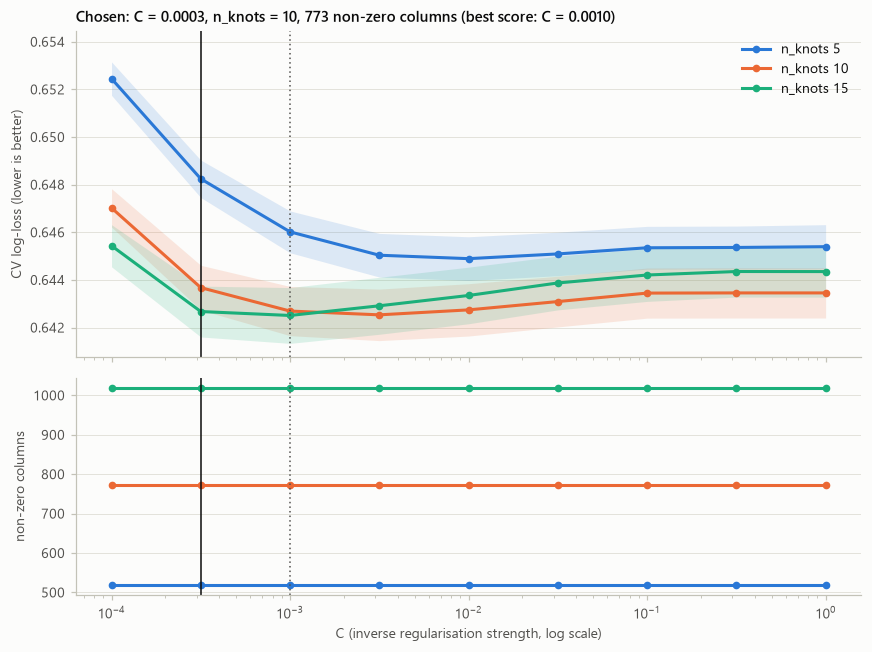

In [3]:
print(f"chosen: {n_knots} knots, C = {C:.4g}, CV log-loss {chosen['loss']:.4f} "
      f"(best: {best['n_knots']:.0f} knots, C = {best['C']:.4g}, {best['loss']:.4f} ± {best['se']:.4f})")
fig = plots.plot_cv_path(path, best, chosen, by="n_knots")

**Takeaway:** **10 knots with C = 3·10⁻⁴**, CV log-loss 0.6437.
- **5 knots are too coarse**: their best loss is 0.6449, 0.0024 behind and outside the one-SE band. Four intervals per variable cannot draw a one-month peak in tenure or a step in handset age.
- **15 knots add nothing over 10**: both reach 0.6425 (15 knots at C = 0.001, 10 knots at C = 0.0032). The one-SE rule takes 10 knots and then the strongest penalty still inside the band, 0.6425 + 0.0012 = 0.6437: C = 3·10⁻⁴, the smoothest curves at equal accuracy.
- The penalty matters only at the strong end. From C = 0.001 to 1 the loss moves by 0.001–0.002, because 80,000 customers are enough to estimate 770 weights. At C = 10⁻⁴ the curves are shrunk too flat and the loss rises.
- 773 non-zero columns out of 993: on zero-inflated variables (data counters, call forwarding, customer care, data overage) several quantile knots coincide, so 220 basis columns are constant and get no weight.

## 3. GAM against the logistic regression and XGBoost, in CV
The same 5 folds and the same `cv_metrics` as the other notebooks: the whole pipeline is refitted on every fold, so the differences are **paired**. The logistic regression is the elastic net chosen in `02_modeling` (`model.logistic_final`), XGBoost the model chosen in `03_xgboost` (`model.xgboost_final`: max_depth 4, 757 trees). A fourth run drops the three ratios from the GAM.

Reading the gaps: **logistic → GAM** is what free curves add (non-linearity, one variable at a time); **GAM → XGBoost** is what interactions add (the effect of one variable depending on another). The knots and C were picked on these folds, so the GAM's CV score is very slightly optimistic, as the other two models' were.

In [4]:
cv_lr = model.cv_metrics(logistic_pipeline(), X, y, cfg)
cv_gam = model.cv_metrics(gam_pipeline(C, n_knots), X, y, cfg, n_jobs=g["n_jobs"])
cv_gam0 = model.cv_metrics(gam_pipeline(C, n_knots, ratios=False), X, y, cfg, n_jobs=g["n_jobs"])
cv_xgb = model.cv_metrics(xgb_pipeline(), X, y, cfg)
pd.DataFrame({"logistic M2": summary(cv_lr), "GAM": summary(cv_gam), "XGBoost": summary(cv_xgb),
              "GAM − logistic (paired)": summary(cv_gam - cv_lr), "XGBoost − GAM (paired)": summary(cv_xgb - cv_gam),
              "GAM without ratios": summary(cv_gam0), "ratios: with − without (paired)": summary(cv_gam - cv_gam0)})

,logistic M2,GAM,XGBoost,GAM − logistic (paired),XGBoost − GAM (paired),GAM without ratios,ratios: with − without (paired)
roc_auc,0.6415 ± 0.0013,0.6765 ± 0.0016,0.6964 ± 0.0015,0.0350 ± 0.0011,0.0199 ± 0.0007,0.6747 ± 0.0019,0.0018 ± 0.0005
pr_auc,0.6279 ± 0.0012,0.6576 ± 0.0015,0.6820 ± 0.0024,0.0297 ± 0.0006,0.0244 ± 0.0013,0.6541 ± 0.0018,0.0035 ± 0.0004
log_loss,0.6618 ± 0.0005,0.6437 ± 0.0009,0.6301 ± 0.0011,-0.0181 ± 0.0006,-0.0136 ± 0.0005,0.6450 ± 0.0010,-0.0013 ± 0.0001
precision,0.6026 ± 0.0011,0.6247 ± 0.0010,0.6351 ± 0.0009,0.0221 ± 0.0009,0.0103 ± 0.0007,0.6228 ± 0.0015,0.0019 ± 0.0008
recall,0.5764 ± 0.0027,0.6264 ± 0.0023,0.6446 ± 0.0030,0.0500 ± 0.0023,0.0182 ± 0.0020,0.6332 ± 0.0032,-0.0068 ± 0.0016
f1,0.5892 ± 0.0017,0.6256 ± 0.0015,0.6398 ± 0.0018,0.0363 ± 0.0012,0.0142 ± 0.0010,0.6279 ± 0.0023,-0.0024 ± 0.0011


In [5]:
# Share of XGBoost's gain over the logistic regression that the additive curves already capture, per fold.
share = (cv_gam - cv_lr) / (cv_xgb - cv_lr)
gap = cv_xgb["roc_auc"] - cv_gam["roc_auc"]
print(f"ROC-AUC gain captured by the GAM: {share['roc_auc'].mean():.0%} ± {share['roc_auc'].sem():.0%}; "
      f"log-loss gain: {share['log_loss'].mean():.0%} ± {share['log_loss'].sem():.0%}")
print(f"decision rule: XGBoost − GAM = {gap.mean():.4f} ROC-AUC, paired SE {gap.sem():.4f} -> "
      + ("the GAM is within one SE: it would replace XGBoost" if gap.mean() <= gap.sem() else "XGBoost stays"))

ROC-AUC gain captured by the GAM: 64% ± 1%; log-loss gain: 57% ± 1%
decision rule: XGBoost − GAM = 0.0199 ROC-AUC, paired SE 0.0007 -> XGBoost stays


**Takeaway:** **the GAM sits between the two: ROC-AUC 0.677, against 0.642 for the logistic regression and 0.696 for XGBoost.** Both gaps are far outside the noise: +0.035 (paired SE 0.0011) over the linear model and −0.020 (paired SE 0.0007) below XGBoost. Every metric falls in the same order.
- **About two thirds of XGBoost's gain is shapes, one third is interactions.** Free curves, one variable at a time, recover 64% ± 1% of XGBoost's ROC-AUC gain over the logistic regression and 57% of its log-loss gain. The rest needs the effect of one variable to depend on another. This is consistent with `03_xgboost`, where depth 2 (pairwise interactions at most) was clearly worse than depth 4.
- **Decision, on CV and before the hold-out: XGBoost stays the pipeline model.** It is 0.020 ahead, about 28 paired SEs.
- **The ratios help the GAM, unlike the other two models**: +0.0018 ± 0.0005 ROC-AUC and −0.0013 ± 0.0001 log-loss. An additive model draws f(minutes) + g(lifetime average) but cannot draw a curve of their ratio, and the effect of usage against the customer's own history is strongly curved (section 6). The logistic regression only needed a straight line in log a − log b, and the trees approximate the ratio with splits. (Recall at 0.5 falls by 0.007 while precision rises: the scores shift around the threshold, and the ranking improves.)

## 4. Hold-out set: scored once
Everything above is frozen. The three pipelines are fitted on the whole training set and score the 20,000 hold-out customers; the logistic and XGBoost numbers are the same as in their own notebooks (same data, same seed) and are repeated to compare the three models on the same customers. Precision, recall and F1 use the 0.5 threshold; only ROC-AUC does not depend on the ~50% churn prevalence of this sample.

In [6]:
X_test, y_test = model.split_xy(test, cfg)
final, xgb, linear = gam_pipeline(C, n_knots).fit(X, y), xgb_pipeline().fit(X, y), logistic_pipeline().fit(X, y)
proba = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in
         {"GAM": final, "XGBoost": xgb, "logistic M2": linear}.items()}
holdout = pd.DataFrame({name: model.metrics(y_test, p, m["threshold"]) for name, p in proba.items()})
holdout.assign(**{"GAM − logistic": holdout["GAM"] - holdout["logistic M2"],
                  "XGBoost − GAM": holdout["XGBoost"] - holdout["GAM"],
                  "GAM CV mean": cv_gam.mean(), "GAM CV SE": cv_gam.sem()})

,GAM,XGBoost,logistic M2,GAM − logistic,XGBoost − GAM,GAM CV mean,GAM CV SE
roc_auc,0.6787,0.6960,0.6417,0.0370,0.0173,0.6765,0.0016
pr_auc,0.6632,0.6848,0.6287,0.0344,0.0217,0.6576,0.0015
log_loss,0.6423,0.6298,0.6616,-0.0193,-0.0125,0.6437,0.0009
precision,0.6254,0.6333,0.6052,0.0202,0.0079,0.6247,0.0010
recall,0.6252,0.6430,0.5778,0.0474,0.0178,0.6264,0.0023
f1,0.6253,0.6381,0.5912,0.0341,0.0128,0.6256,0.0015


In [7]:
# A retention campaign contacts the k% riskiest customers: precision = share of them who would churn,
# recall = share of all churners reached. On this ~50% sample a random list has precision 0.50 and recall k.
def top_share(y_true: np.ndarray, p: np.ndarray, share: float) -> pd.Series:
    picked = p >= np.quantile(p, 1 - share)
    return pd.Series({"precision": y_true[picked].mean(), "recall": y_true[picked].sum() / y_true.sum()})


pd.concat({name: pd.DataFrame({f"top {q:.0%}": top_share(y_test.to_numpy(), p, q) for q in (0.1, 0.2, 0.3, 0.5)})
           for name, p in proba.items()})

top 10%  top 20%  top 30%  top 50%
GAM         precision   0.7565   0.7173   0.6798   0.6251
            recall      0.1526   0.2894   0.4115   0.6306
XGBoost     precision   0.7930   0.7348   0.6987   0.6342
            recall      0.1600   0.2965   0.4229   0.6398
logistic M2 precision   0.7135   0.6677   0.6403   0.5989
            recall      0.1440   0.2695   0.3876   0.6042

**Takeaway:** on the 20,000 hold-out customers the GAM scores **ROC-AUC 0.679**, PR-AUC 0.663, log-loss 0.642, precision 0.625, recall 0.625, F1 0.625. That is within the CV noise (0.6765 ± 0.0016), so the knots and C chosen on the folds did not overfit them.
- The three models keep their CV order on every metric: the GAM is +0.037 ROC-AUC over the logistic regression and −0.017 below XGBoost.
- **Campaign view**: among the 10% riskiest customers by the GAM, 76% churn (XGBoost 79%, logistic 71%, a random list 50%), and they are 15% of all churners. At 20%, 72% against 73% for XGBoost. The gap narrows as the list widens: at 50%, precision is 0.625 against 0.634.
- So a fully transparent model gives up about 4 points of precision in the top 10%, about 2 in the top 20–30% and 1 at 50%.

## 5. What the GAM uses: exact contributions on the hold-out set
A GAM is additive, so a customer's log-odds split **exactly** into one contribution per variable: the variable's curve at the customer's value, minus its average over the training customers. That is the variable's exact SHAP value, with no sampling and no approximation (`model.contributions`, the same function as the logistic regression: for a spline variable it sums its basis columns). A variable's **importance is its mean |contribution|** over the hold-out customers, in log-odds, the same scale as XGBoost's mean |SHAP|.
- A missing numeric value gets the curve at the training median plus its block indicator (`… (missing)`): the indicator carries the effect of being missing.
- (+) / (−): the Spearman correlation between the value and its contribution is at least 0.5 in absolute value (`shap.monotonic_rho`); no sign = not monotonic (look at its curve in section 6), or categorical.
- As for SHAP: **the model, not the world**. Near-duplicates share the credit, and with free curves they can offset each other, so read families as well as single variables.

intercept -0.019 log-odds (p = 0.495); max |intercept + sum of contributions - model log-odds| = 2.7e-15


109 variables; share of the total importance: top 10 34%, top 20 51%; variables with importance < 0.01: 30


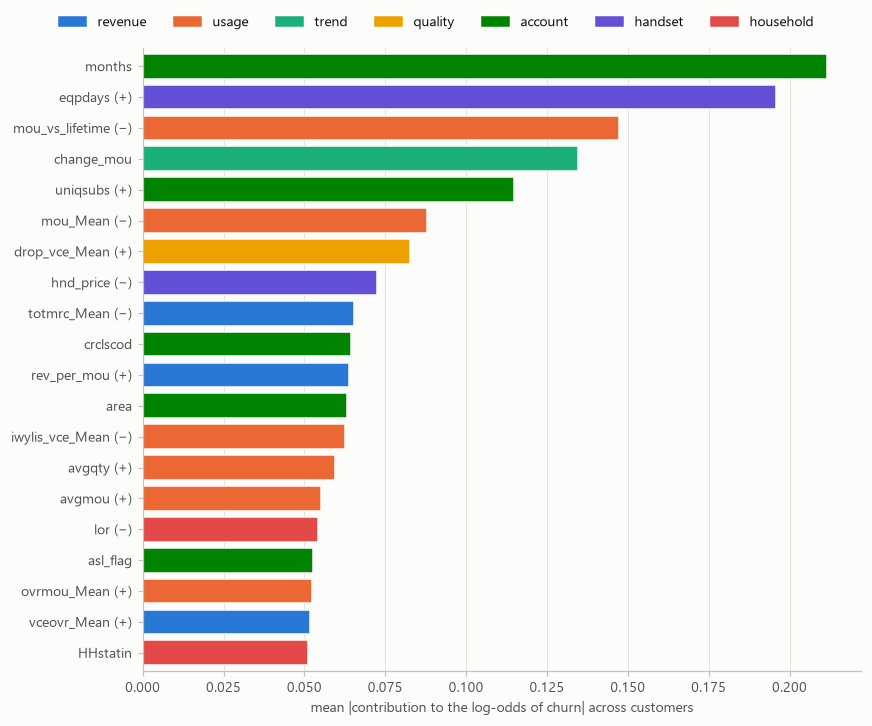

In [8]:
contrib = model.contributions(final, X_test)
base = float(final[-1].intercept_[0])
# The model's inputs before encoding: cleaned values and the ratios (categoricals as their levels).
values = final[:2].transform(X_test)
numeric_values = values.select_dtypes("number")
print(f"intercept {base:.3f} log-odds (p = {expit(base):.3f}); max |intercept + sum of contributions - model "
      f"log-odds| = {np.abs(base + contrib.sum(axis=1) - final.decision_function(X_test)).max():.1e}")
imp = model.shap_importance(contrib, numeric_values, cfg["families"], s["monotonic_rho"])
total = imp["importance"].sum()
print(f"{len(imp)} variables; share of the total importance: top 10 {imp['importance'].head(10).sum() / total:.0%}, "
      f"top 20 {imp['importance'].head(20).sum() / total:.0%}; variables with importance < 0.01: "
      f"{(imp['importance'] < 0.01).sum()}")
fig = plots.plot_importance(imp, colors, s["top_n"])

In [9]:
# Importance per family for the three models, all on the hold-out customers.
xgb_contrib, xgb_base = model.tree_contributions(xgb, X_test)
xgb_imp = model.shap_importance(xgb_contrib, numeric_values, cfg["families"], s["monotonic_rho"])
lin_imp = model.importance(linear, X_test, cfg["families"])
fam = pd.DataFrame({name: i.groupby("family")["importance"].sum()
                    for name, i in {"GAM": imp, "XGBoost": xgb_imp, "logistic M2": lin_imp}.items()})
(fam / fam.sum()).sort_values("GAM", ascending=False).rename(columns=lambda c: f"{c} share")

,GAM share,XGBoost share,logistic M2 share
family,,,
usage,0.3570,0.2969,0.3650
account,0.1606,0.1675,0.1686
revenue,0.1351,0.1466,0.1201
handset,0.1232,0.1575,0.1153
household,0.1015,0.0890,0.1217
trend,0.0542,0.0781,0.0512
quality,0.0495,0.0531,0.0512
care,0.0189,0.0114,0.0068


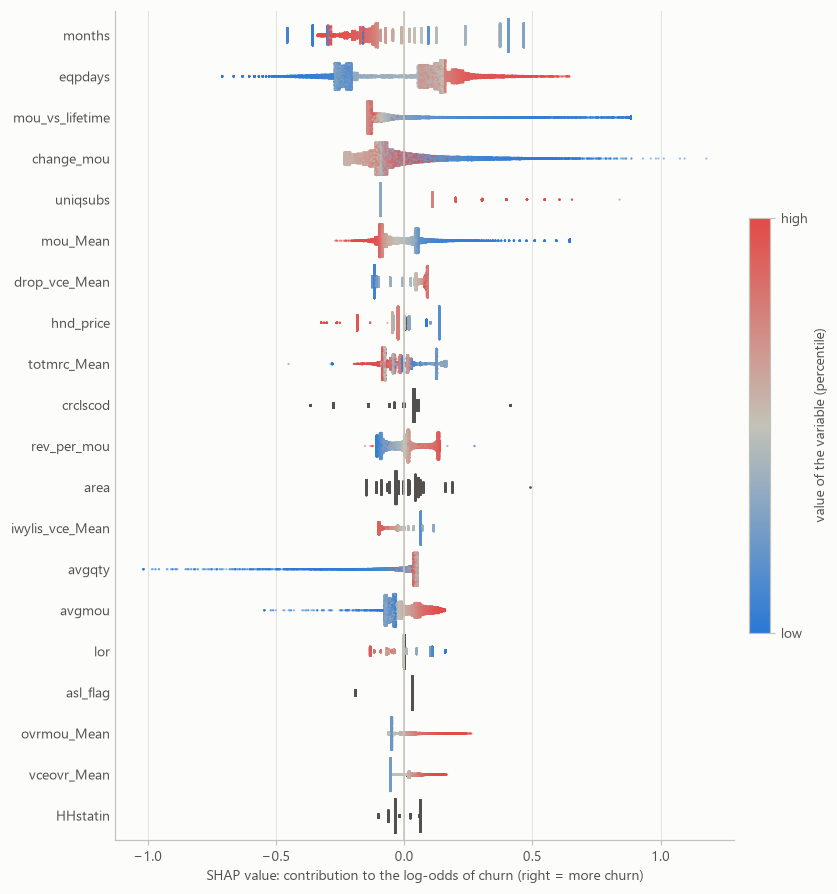

In [10]:
fig = plots.plot_beeswarm(contrib, values, list(imp.index[: s["top_n"]]), cfg["seed"])

**Takeaway:** **the same top 5 as XGBoost**: tenure (`months`, 0.21 log-odds on average), handset age (`eqpdays`, 0.20), usage against the customer's own history (`mou_vs_lifetime`, 0.15), the usage trend (`change_mou`, 0.13) and extra subscribers (`uniqsubs`, 0.11). Tenure and handset age swap places: the GAM cannot draw the sharp step in handset age (section 7), so it gets less out of it (0.20 against 0.25 in XGBoost).
- The additivity is exact to float64 rounding: intercept + contributions rebuild each log-odds within 3·10⁻¹⁵ (TreeSHAP: 5·10⁻⁶, float32).
- **Importance is more spread out than in XGBoost.** The top 10 carry 34% of the total (XGBoost 47%) and the top 20 carry 51% (64%); 30 of 109 variables average less than 0.01. The ridge penalty spreads credit over near-duplicates instead of picking one: `mou_Mean` is 6th here and 28th in XGBoost, `avgmou` 15th against 60th, `iwylis_vce_Mean` 13th against 20th.
- **Families** are close to XGBoost's: usage 36% (XGBoost 30%; the logistic regression, which also splits usage among twins, 37%), account 16% (17%), revenue 14% (15%), handset 12% (16%), household 10% (9%), trend 5% (8%), quality 5% (5%), care 2% (1%).
- **Reading the beeswarm**:
  - `months` shows one vertical bar per month; the bars far right are months 11–13.
  - `eqpdays` splits into two clusters again, below and above about 300 days.
  - `mou_vs_lifetime` and `change_mou` have long right tails: a usage collapse adds up to +0.9 and +1.2 log-odds.
  - `avgqty` and `avgmou` have long left tails (low lifetime averages pull down to −1.0). These are corrections among usage twins, which share and offset the usage signal, not a standalone "few calls protect" effect; XGBoost gives `avgmou` almost nothing (60th).

## 6. The curves, and how much they move
Each panel is a variable's curve: its contribution (log-odds) against its value, for every hold-out customer, on a shared y axis so the sizes compare. In a GAM the dots lie on the curve, because the contribution depends on that variable alone. The thin blue lines are the same GAM **refitted on each of the 5 CV training splits** and read on the same customers: where they overlap the black line, the shape does not depend on which customers trained it. (The splits share 75% of their customers, so the spread is a lower bound on the uncertainty, not a confidence interval.)

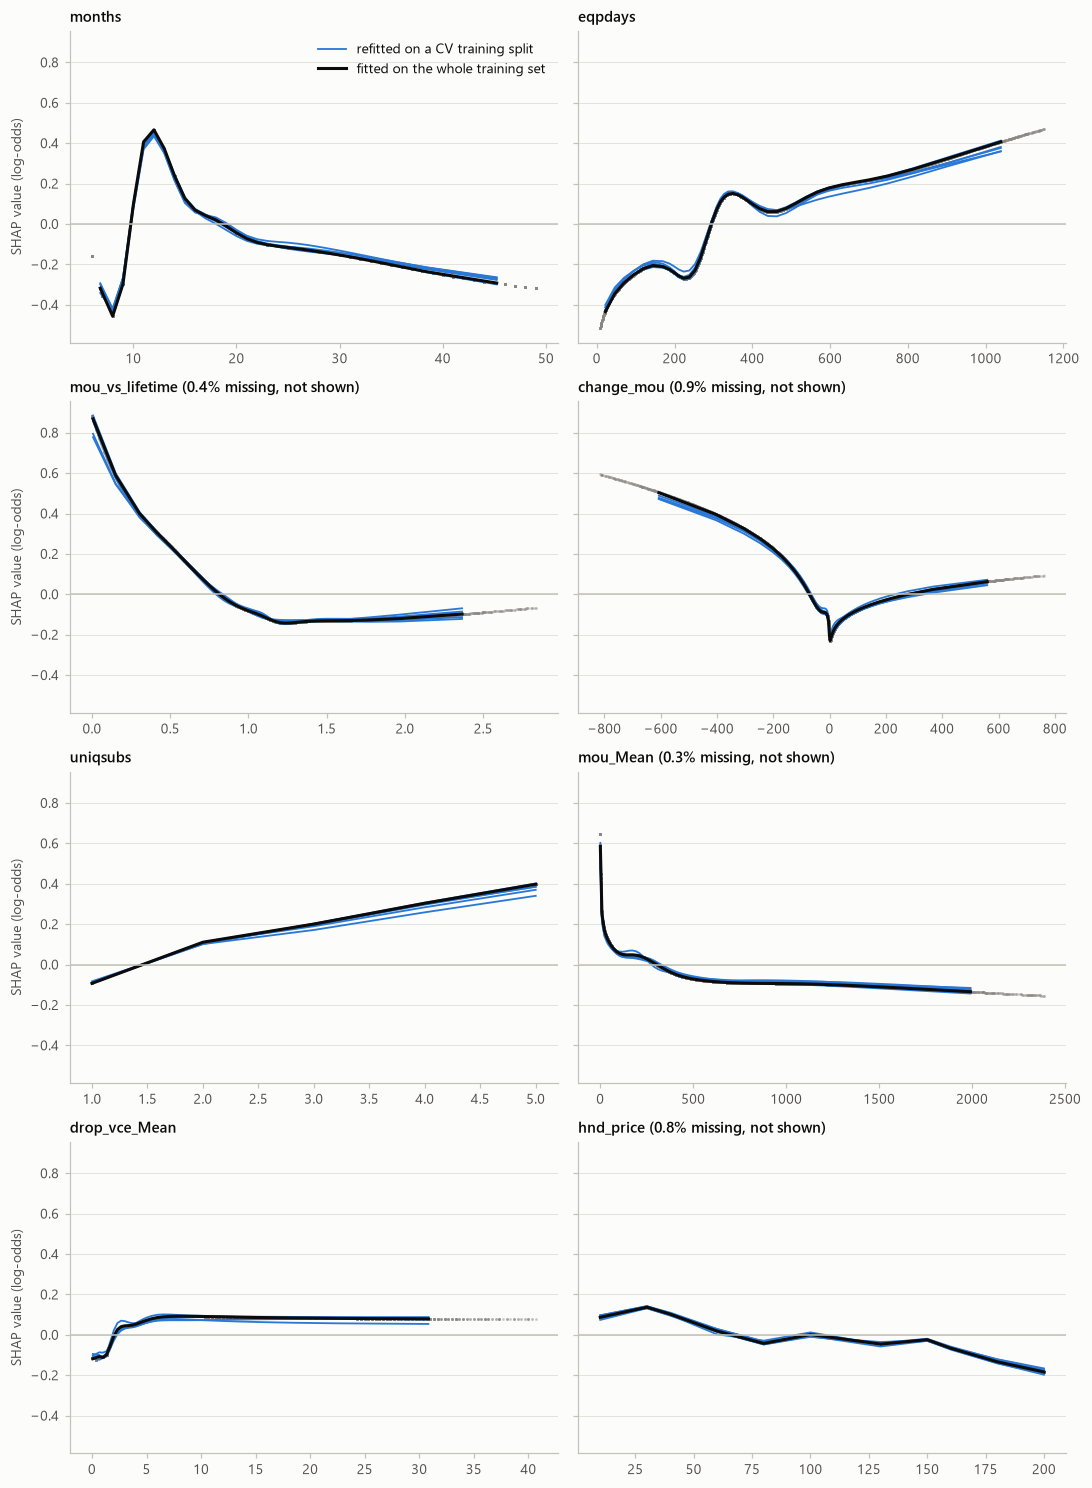

In [11]:
numeric = [v for v in imp.index if v in numeric_values]
fold_contrib = model.fold_contributions(gam_pipeline(C, n_knots), X, y, X_test, cfg)
fig = plots.plot_dependence(contrib, values, numeric[:8], curves={"refitted on a CV training split": fold_contrib},
                            label="fitted on the whole training set")

In [12]:
# How much the curves and the ranking move across the 5 refits.
lead = numeric[:8]
moves = pd.DataFrame({f"fold {k}": (c[lead] - contrib[lead]).abs().mean() for k, c in enumerate(fold_contrib, 1)})
fold_imp = pd.DataFrame({f"fold {k}": c.abs().mean() for k, c in enumerate(fold_contrib, 1)})
print("Spearman correlation of each refit's importance ranking with the final one (all variables):",
      fold_imp.corrwith(imp["importance"], method="spearman").round(3).to_dict())
pd.DataFrame({"importance": imp.loc[lead, "importance"], "largest mean |refit - final|": moves.max(axis=1)}).assign(
    relative=lambda d: d.iloc[:, 1] / d["importance"])

Spearman correlation of each refit's importance ranking with the final one (all variables): {'fold 1': 0.982, 'fold 2': 0.981, 'fold 3': 0.985, 'fold 4': 0.981, 'fold 5': 0.98}


,importance,largest mean |refit - final|,relative
months,0.2116,0.0191,0.0905
eqpdays,0.1958,0.0220,0.1122
mou_vs_lifetime,0.1472,0.0095,0.0649
change_mou,0.1347,0.0129,0.0955
uniqsubs,0.1149,0.0127,0.1103
mou_Mean,0.0878,0.0130,0.1481
drop_vce_Mean,0.0827,0.0134,0.1620
hnd_price,0.0724,0.0076,0.1054


**Takeaway:** **the shapes do not depend on which customers trained the model.** The 5 refits lie on the final curve almost everywhere: their largest mean deviation is 6–16% of the variable's importance (`mou_vs_lifetime` 6%, `months` 9%, `eqpdays` 11%, `drop_vce_Mean` 16%). Each refit's ranking of all 109 variables correlates 0.98 with the final one, as stable as XGBoost's (0.97–0.98).
- **Tenure**: a dip at 7–9 months (−0.30 to −0.46), a steep rise to a **peak at 11–12 months** (+0.41, +0.47), back to zero at about 19 months, then slowly protective (−0.3 at 45 months). Month 8 → 12 is +0.92 log-odds, odds ×2.5: the same size as XGBoost's month 9 → 11.
- **Handset age**: low below about 250 days, **a rise between 250 and 330 days**, then high and still rising slowly (+0.4 at 1,000 days). The hump and dip at 150–250 days is the spline ringing around a step it cannot draw sharply; read the curve as "below ~280 days low, above ~300 high".
- **Usage against own history**: a steady slope from +0.88 at zero usage to 0 at about 80% of the usual, flat and protective (−0.1) above it.
- **Usage trend**: a V with its minimum at no change (−0.2). Any drop raises the risk (+0.5 at −600 minutes); large increases raise it slightly (+0.07 at +600).
- **Subscribers**: almost linear, +0.11 at 2, +0.20 at 3, +0.33 at 4–5.
- **Minutes this month** (`mou_Mean`): a spike at zero (+0.6), the second half of the zero-usage signal; flat (−0.1) above about 300 minutes.
- **Dropped voice calls are a threshold, not a slope**: from −0.1 with 0–2 drops a month to +0.08 from about 5, and flat after that. The first few dropped calls are what matters.
- **Handset price**: $30 handsets +0.13, $200 −0.19.

## 7. Does the GAM draw the same shapes as XGBoost?
The orange line is XGBoost's mean SHAP value per bin (its dependence curve from `03_xgboost`), the black line the GAM's curve, on the same hold-out customers. XGBoost's curve averages over interactions; the GAM's has none. **Where the two agree, the effect is a main effect and does not depend on the model; where they differ, either the GAM's knots are too coarse or the effect depends on other variables.** The tables give both in numbers, per band, next to the observed hold-out churn rate; the last table measures the agreement for every top variable.

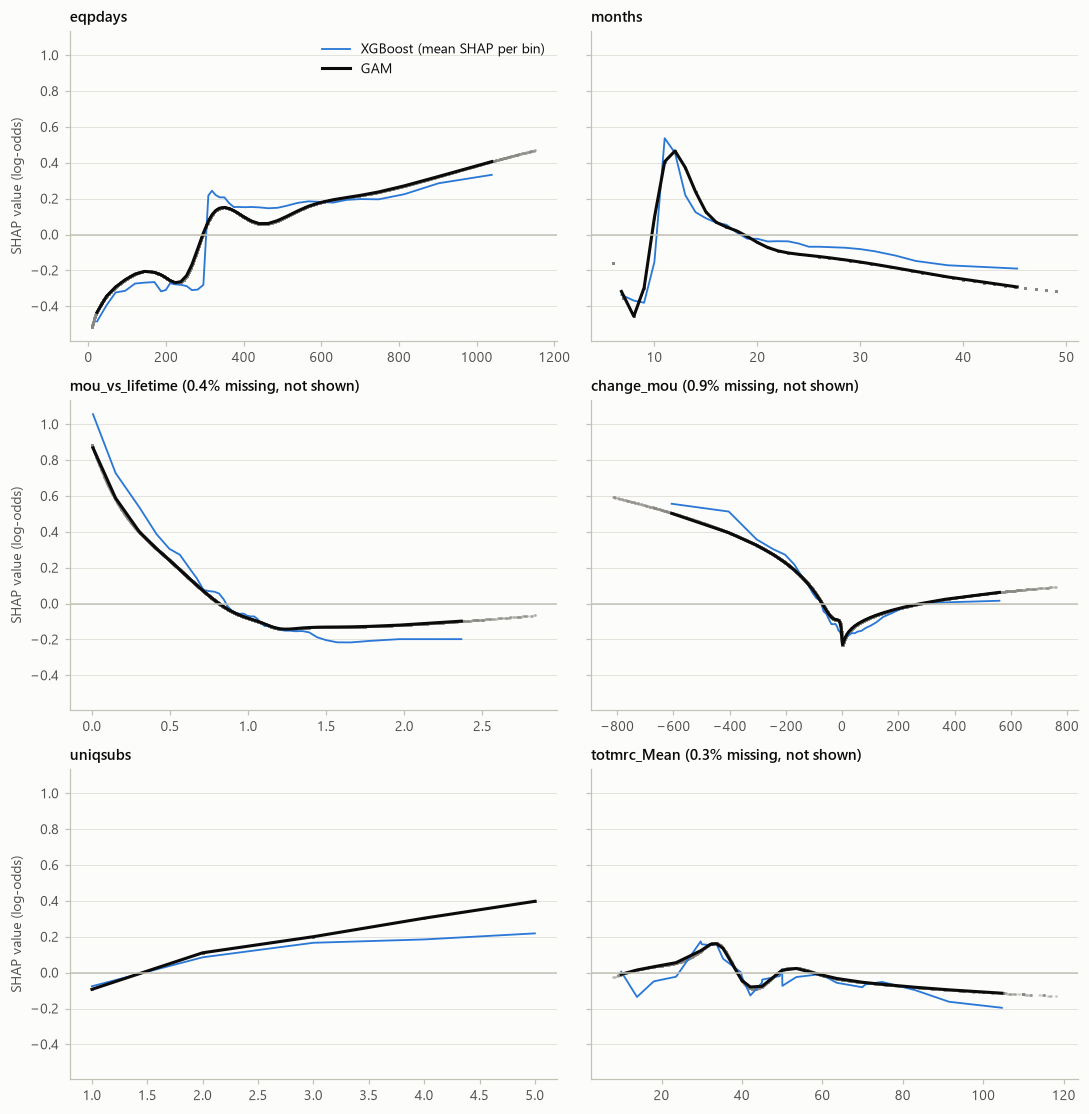

In [13]:
shared = ["eqpdays", "months", "mou_vs_lifetime", "change_mou", "uniqsubs", "totmrc_Mean"]
fig = plots.plot_dependence(contrib, values, shared, curves={"XGBoost (mean SHAP per bin)": xgb_contrib}, label="GAM")

In [14]:
# Tenure, month by month (log-odds): the GAM's curve against XGBoost's mean SHAP.
months = pd.DataFrame({"GAM": contrib["months"], "XGBoost": xgb_contrib["months"], "churn_rate": y_test})
by_month = months.groupby(values["months"])
by_month.mean().assign(customers=by_month.size()).loc[6:24].T

months,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
GAM,-0.1601,-0.3565,-0.4559,-0.2973,0.0938,0.4067,0.4663,0.3738,0.2383,0.1263,0.0685,0.0418,0.0203,-0.0102,-0.0438,-0.0722,-0.0910,-0.1026,-0.1102
XGBoost,-0.2844,-0.3496,-0.3683,-0.3803,-0.1532,0.5373,0.4555,0.2199,0.1245,0.0909,0.0665,0.0543,0.0112,-0.0230,-0.0238,-0.0386,-0.0370,-0.0379,-0.0499
churn_rate,0.3790,0.3461,0.3014,0.2935,0.3986,0.6634,0.6249,0.5504,0.5414,0.5273,0.5028,0.5113,0.4992,0.4867,0.5158,0.4986,0.5109,0.5089,0.5215
customers,248.0000,994.0000,720.0000,811.0000,828.0000,1622.0000,1189.0000,1161.0000,918.0000,751.0000,722.0000,710.0000,639.0000,787.0000,568.0000,724.0000,550.0000,727.0000,466.0000


In [15]:
# The other variables per band (shap.bands in config.yaml), both models and the hold-out churn rate.
def by_band(col: str, edges: list) -> pd.DataFrame:
    band = pd.cut(values[col], edges, right=False).cat.add_categories("missing").fillna("missing")
    grouped = pd.DataFrame({"GAM": contrib[col], "XGBoost": xgb_contrib[col], "churn_rate": y_test}).groupby(
        band, observed=True)
    return grouped.mean().assign(customers=grouped.size()).T


for col, edges in s["bands"].items():
    display(by_band(col, edges).rename_axis(col, axis=1))

eqpdays,"[0, 240)","[240, 270)","[270, 300)","[300, 330)","[330, 360)","[360, 420)","[420, 600)","[600, 2000)"
GAM,-0.2798,-0.2172,-0.0614,0.0968,0.1481,0.1156,0.1032,0.2754
XGBoost,-0.3281,-0.2959,-0.3052,0.1948,0.2090,0.1548,0.1630,0.2414
churn_rate,0.4023,0.3690,0.3917,0.5933,0.6425,0.5509,0.5282,0.5564
customers,5906.0000,1019.0000,1016.0000,1473.0000,1239.0000,2071.0000,3453.0000,3823.0000


mou_vs_lifetime,"[0.0, 0.01)","[0.01, 0.25)","[0.25, 0.5)","[0.5, 0.75)","[0.75, 0.85)","[0.85, 1.1)","[1.1, 1.5)","[1.5, 100.0)",missing
GAM,0.8827,0.6180,0.3279,0.1272,0.0085,-0.0732,-0.1338,-0.1134,-0.0905
XGBoost,1.0810,0.7598,0.4277,0.1718,0.0571,-0.0639,-0.1504,-0.2069,0.3587
churn_rate,0.7995,0.6703,0.6148,0.5521,0.4719,0.4599,0.4622,0.4548,0.7042
customers,389.0000,637.0000,1220.0000,2436.0000,1602.0000,5206.0000,5565.0000,2874.0000,71.0000


change_mou,"[-5000, -400)","[-400, -200)","[-200, -100)","[-100, -50)","[-50, 0)","[0, 50)","[50, 100)","[100, 200)","[200, 5000)",missing
GAM,0.5212,0.3007,0.1435,0.0055,-0.0983,-0.1752,-0.0986,-0.0541,0.0275,-0.1100
XGBoost,0.5662,0.3452,0.1530,-0.0117,-0.1334,-0.1775,-0.1451,-0.0833,0.0077,0.6410
churn_rate,0.5478,0.5378,0.5285,0.4861,0.4960,0.4848,0.4635,0.4418,0.4852,0.7630
customers,931.0000,1480.0000,2108.0000,2010.0000,4165.0000,3628.0000,1616.0000,1797.0000,2092.0000,173.0000


uniqsubs,"[1, 2)","[2, 3)","[3, 4)","[4, 6)","[6, 200)"
GAM,-0.0929,0.1108,0.2006,0.3286,0.5176
XGBoost,-0.0758,0.0856,0.1666,0.1941,0.3628
churn_rate,0.4771,0.5220,0.5180,0.5577,0.6400
customers,12426.0000,5498.0000,1309.0000,667.0000,100.0000


totmrc_Mean,"[-100, 20)","[20, 30)","[30, 40)","[40, 60)","[60, 75)","[75, 100)","[100, 500)",missing
GAM,-0.0080,0.1118,0.0624,-0.0300,-0.0493,-0.0842,-0.1376,-0.0758
XGBoost,-0.0409,0.1431,0.0793,-0.0332,-0.0706,-0.1140,-0.1950,-0.2913
churn_rate,0.5341,0.5563,0.5280,0.4775,0.4143,0.4428,0.4057,0.6719
customers,2256.0000,2441.0000,4193.0000,7504.0000,1581.0000,1574.0000,387.0000,64.0000


lor,"[0, 2)","[2, 4)","[4, 6)","[6, 10)","[10, 20)",missing
GAM,0.1190,0.0809,0.0034,-0.0537,-0.1076,-0.0013
XGBoost,0.1022,0.0605,-0.0318,-0.0780,-0.1485,0.0583
churn_rate,0.5249,0.5066,0.4919,0.4796,0.4548,0.5118
customers,2374.0000,2975.0000,2049.0000,3086.0000,3492.0000,6024.0000


hnd_price,"[0, 30)","[30, 60)","[60, 100)","[100, 160)","[160, 1000)",missing
GAM,0.1289,0.0248,-0.0227,-0.0322,-0.1896,0.0017
XGBoost,0.1451,0.0156,-0.0052,-0.0337,-0.1863,-0.2392
churn_rate,0.5673,0.5302,0.4932,0.4635,0.4167,0.3245
customers,5181.0000,1905.0000,3449.0000,7092.0000,2222.0000,151.0000


In [16]:
# Being missing: the "missing" columns above show only the GAM's curve at the training median. The effect of the
# value being missing sits in the block indicator, read here on the hold-out customers whose block is missing.
rows = {}
for v in [c for c in contrib if c.endswith(" (missing)")]:
    missing = values[v.removesuffix(" (missing)")].isna()
    rows[v] = {"customers": missing.sum(), "churn_rate": y_test[missing].mean(),
               "contribution when missing": contrib.loc[missing, v].mean(), "gam_rank": imp.index.get_loc(v) + 1}
pd.DataFrame(rows).T.sort_values("gam_rank")

,customers,churn_rate,contribution when missing,gam_rank
lor (missing),6024.0000,0.5118,0.0286,64.0000
change_mou (missing),173.0000,0.7630,0.9666,65.0000
avg6mou (missing),569.0000,0.4095,0.1319,82.0000
income (missing),5065.0000,0.5104,-0.0118,88.0000
hnd_price (missing),151.0000,0.3245,-0.3008,91.0000
adults (missing),4570.0000,0.5147,-0.0050,101.0000
numbcars (missing),9856.0000,0.5030,-0.0017,104.0000
rev_Mean (missing),64.0000,0.6719,0.1733,105.0000
truck (missing),323.0000,0.5232,-0.0347,106.0000


In [17]:
# Agreement per variable over the hold-out customers: correlation between the GAM contribution and the XGBoost SHAP
# value, and the two importances and ranks. Top 15 of either model.
top = list(dict.fromkeys([*imp.index[:15], *xgb_imp.index[:15]]))
pd.DataFrame({"gam_rank": imp.index.get_indexer(top) + 1, "xgb_rank": xgb_imp.index.get_indexer(top) + 1,
              "gam_importance": imp.loc[top, "importance"], "xgb_importance": xgb_imp.loc[top, "importance"],
              "correlation": [contrib[v].corr(xgb_contrib[v]) for v in top],
              "gam_direction": imp.loc[top, "direction"], "xgb_direction": xgb_imp.loc[top, "direction"]}, index=top)

,gam_rank,xgb_rank,gam_importance,xgb_importance,correlation,gam_direction,xgb_direction
months,1,2,0.2116,0.1887,0.9067,,
eqpdays,2,1,0.1958,0.2477,0.9258,+,+
mou_vs_lifetime,3,3,0.1472,0.1867,0.9620,-,-
change_mou,4,4,0.1347,0.1623,0.8855,,
uniqsubs,5,5,0.1149,0.0899,0.9346,+,+
mou_Mean,6,28,0.0878,0.0264,0.7644,-,-
drop_vce_Mean,7,10,0.0827,0.0640,0.9403,+,+
hnd_price,8,8,0.0724,0.0792,0.9033,-,-
totmrc_Mean,9,6,0.0653,0.0880,0.7544,-,
crclscod,10,11,0.0644,0.0571,0.9533,,


In [18]:
both = imp.index.intersection(xgb_imp.index)
print(f"Spearman correlation of the importance rankings over the {len(both)} shared variables: "
      f"GAM vs XGBoost {imp.loc[both, 'importance'].corr(xgb_imp.loc[both, 'importance'], method='spearman'):.2f}, "
      f"GAM vs logistic {imp.loc[both, 'importance'].corr(lin_imp.loc[both, 'importance'], method='spearman'):.2f}")

Spearman correlation of the importance rankings over the 100 shared variables: GAM vs XGBoost 0.92, GAM vs logistic 0.62


**Takeaway:** **the two models tell the same story.** Over the 100 shared variables their importance rankings correlate 0.92 (Spearman); the GAM against the logistic regression only 0.62. For the top 5, the GAM contribution and the XGBoost SHAP value of the same customer correlate 0.89–0.96. The drivers the recommendations rest on do not depend on the model.
- **Where they agree**:
  - the tenure peak: +0.41 / +0.47 at months 11 / 12 in the GAM, +0.54 / +0.46 in XGBoost;
  - the usage slope and its protective plateau above ~85% of the usual;
  - the V in the usage trend, with the minimum at no change in both;
  - the plan-fee bump: $20–30 +0.11 (XGBoost +0.14), $100 or more −0.14 (−0.20);
  - years at the address and handset price, nearly identical band by band.
- **Where they differ, and why**:
  - **Handset age**: XGBoost draws a sharp step at 300 days ([270, 300): −0.31, [300, 330): +0.19). The GAM's cubic pieces spread it over 250–330 days (−0.06 and +0.10). Smoothing has a cost here, and it is part of the AUC the GAM loses. The business reading is the same: the change happens around day 300.
  - **Month 10**: GAM +0.09, XGBoost −0.15, observed churn 40% (as low as months 6–9). The GAM's rise starts a month early, again from smoothing, and XGBoost is closer to the data.
  - **Tails**: the GAM keeps the trend going where customers are few: 6+ subscribers +0.52 against +0.36 (100 customers); handsets over 600 days keep rising. XGBoost flattens at the edges.
  - **Usage twins**: XGBoost takes usage mostly through the ratio; the GAM spreads it over `mou_Mean`, `avgmou` and `avgqty`, which partly offset each other (`avgmou`: correlation −0.13 with XGBoost). Read the usage family as one driver.
  - **Missing values**: XGBoost puts the effect of a missing value into the variable's own SHAP value (`change_mou` missing: +0.64, churn 76%); the GAM puts it into the block indicator (last table). For the 173 customers with no usage trend recorded (churn 76%) the indicator adds **+0.97**, more than XGBoost's +0.64; a missing handset price (151 customers, churn 32%) gives −0.30 (XGBoost −0.24). The indicators rank low on average importance (64th and below) only because few customers are missing: for those few the effect is among the largest in the model.

## 8. One customer at a time
The GAM's contributions read for one customer: the waterfall starts from the intercept and adds one bar per variable, the 10 largest first and the rest summed, until it reaches the customer's own log-odds. In a GAM each bar is a point on that variable's curve, so it can be read straight off the panels above. Two hold-out customers chosen on the GAM's score, one at the 99th percentile of risk and one at the median, and for the first one also XGBoost's explanation, to see whether the two models give the same reasons. The values shown are the model's inputs after cleaning; no identifier is shown.

high-risk customer: GAM p = 0.83, XGBoost p = 0.85, churned: True


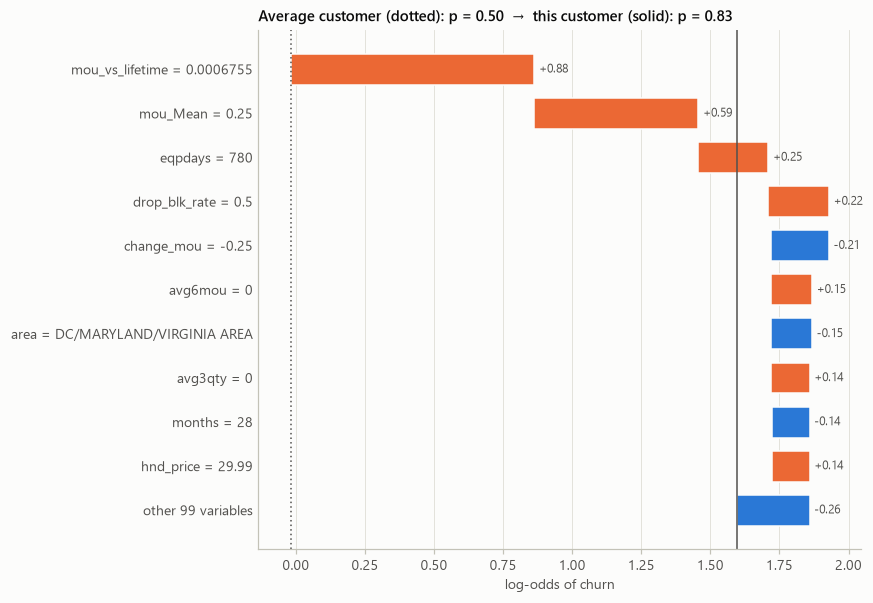

In [19]:
p = pd.Series(proba["GAM"], index=X_test.index)
p_xgb = pd.Series(proba["XGBoost"], index=X_test.index)
high, typical = (p - p.quantile(0.99)).abs().idxmin(), (p - p.median()).abs().idxmin()
print(f"high-risk customer: GAM p = {p[high]:.2f}, XGBoost p = {p_xgb[high]:.2f}, churned: {bool(y_test[high])}")
fig = plots.plot_waterfall(contrib.loc[high], values.loc[high], base)

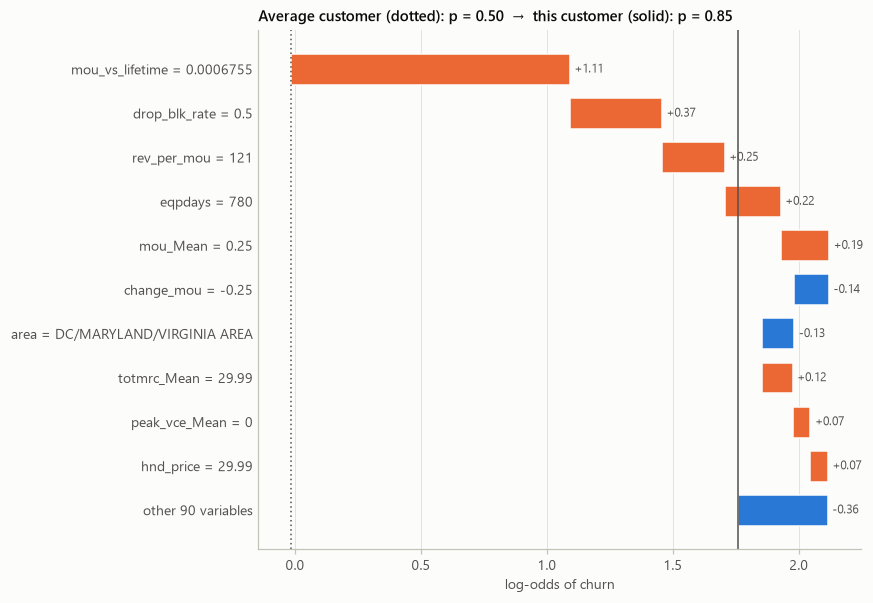

In [20]:
fig = plots.plot_waterfall(xgb_contrib.loc[high], values.loc[high], xgb_base)

typical customer: GAM p = 0.50, XGBoost p = 0.48, churned: True


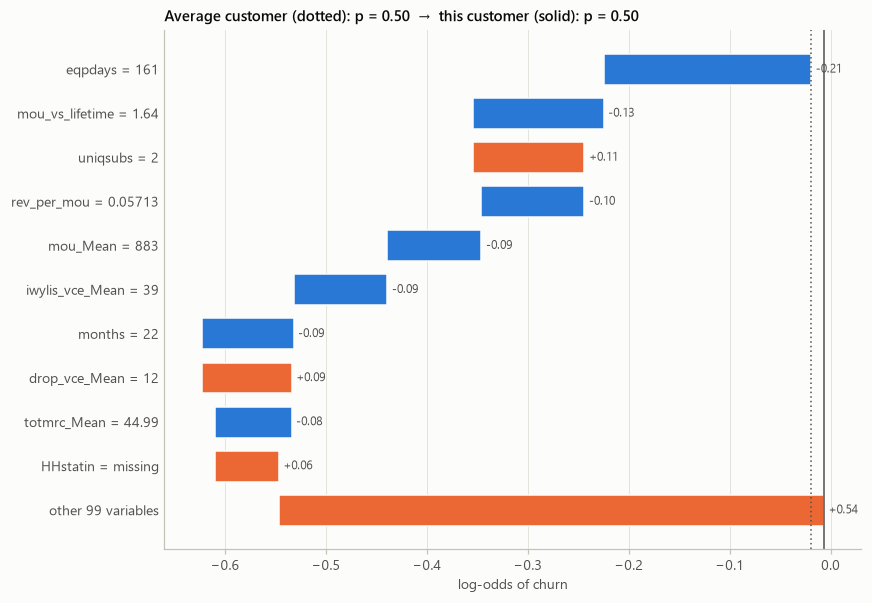

In [21]:
print(f"typical customer: GAM p = {p[typical]:.2f}, XGBoost p = {p_xgb[typical]:.2f}, churned: {bool(y_test[typical])}")
fig = plots.plot_waterfall(contrib.loc[typical], values.loc[typical], base)

**Takeaway:** **for a high-risk customer the two models give the same reasons.**
- **High-risk customer (GAM p = 0.83, XGBoost p = 0.85, churned).**
  - Usage has collapsed: `mou_vs_lifetime` ≈ 0 (GAM +0.88, XGBoost +1.11), 0.25 minutes this month (+0.59 and +0.19).
  - The handset is 780 days old (+0.25 and +0.22).
  - Half of the attempted calls were dropped or blocked (`drop_blk_rate` 0.5: +0.22 and +0.37).
  - The split differs only among twins: the GAM puts more on `mou_Mean`, XGBoost more on the ratio and on the price per minute (+0.25).
  - This is the inactive profile of `03_xgboost` again, here with a bad network experience. A quality follow-up could come before an offer, if it is not already too late.
- **Typical customer (GAM p = 0.50, XGBoost p = 0.48, churned).**
  - Pushing the risk down: a young handset (161 days, −0.21), usage above the customer's own average (1.64×, −0.13) and a low price per minute (−0.10).
  - Pushing it up: 2 subscribers (+0.11) and 12 dropped calls a month (+0.09).
  - The other 99 variables add **+0.54** together. The GAM spreads its signal over many small contributions, so for a mid-score customer no single reason dominates. That is a weak basis for a targeted action, and an argument for spending the budget at the top of the list.

## 9. Interactions: does the effect of one variable depend on another?
The GAM above has no interactions by construction: the handset-age curve is the same at 8 months of tenure as at 36. XGBoost is 0.020 ROC-AUC better, and section 3 put that gap down to interactions. This section adds **three interaction surfaces** to the GAM and asks where its curves bend.

**Which pairs.** XGBoost's exact SHAP interaction values rank every pair of variables. They are computed on the training set only: XGBoost is fitted on the first CV training split and read on 3,000 customers of its validation fold, so the hold-out plays no part in the choice. From the top of that ranking, three pairs that read as a business question:
- **handset age × tenure**: is the handset step the same at every point of the contract?
- **handset age × handset price**: does a cheap handset age differently from an expensive one?
- **tenure × monthly plan fee**: is the 11–13-month peak the same on every plan?

`change_mou × mou_vs_lifetime` ranks as high, but it is two measures of the same usage drop, so its interaction would be a correction between twins rather than an insight.

**How.** A **tensor-product spline**: each variable of the pair gets a cubic basis with 5 knots at quantiles (6 columns), and every column of one is multiplied by every column of the other (36 columns). Their weighted sum can draw any smooth surface over the two values, and it is added on top of the two curves, which keep their 10 knots. The products overlap the two curves in part, so the surface is read **jointly** (curve + curve + surface), never the surface term alone. The penalty C is chosen again with the same path and one-SE rule; the knots stay as chosen in section 2.

In [22]:
tr, va = next(model.folds(cfg).split(X, y))
pairs = model.tree_interactions(xgb_pipeline().fit(X.iloc[tr], y.iloc[tr]),
                                X.iloc[va].sample(3000, random_state=cfg["seed"]))
pairs.head(12).to_frame("mean |SHAP interaction| (log-odds)")

,,mean |SHAP interaction| (log-odds)
a,b,
months,eqpdays,0.0778
hnd_price,eqpdays,0.0421
change_mou,mou_vs_lifetime,0.0420
totmrc_Mean,months,0.0387
rev_Mean,totmrc_Mean,0.0271
totmrc_Mean,avgrev,0.0253
change_mou,rev_per_mou,0.0230
eqpdays,refurb_new,0.0210
iwylis_vce_Mean,mouiwylisv_Mean,0.0201


In [23]:
T = g["tensors"]


def gam_t_pipeline(C: float):
    return model.build_pipeline(cfg, model.gam(cfg, C), n_knots=n_knots, tensors=T)


Z = gam_t_pipeline(1.0)[:-1].fit_transform(X, y)
path_t = model.cv_path(model.gam_cv(cfg).fit(Z, y)).assign(loss=lambda p: -p["score"])
del Z
best_t, chosen_t = path_t.loc[path_t["score"].idxmax()], model.pick_one_se(path_t)
C_t = float(chosen_t["C"])
print(f"chosen C = {C_t:.4g}, CV log-loss {chosen_t['loss']:.4f} (best: C = {best_t['C']:.4g}, "
      f"{best_t['loss']:.4f} ± {best_t['se']:.4f}); {chosen_t['n_nonzero']:.0f} non-zero columns")
cv_gam_t = model.cv_metrics(gam_t_pipeline(C_t), X, y, cfg, n_jobs=g["n_jobs"])
closed = (cv_gam_t - cv_gam) / (cv_xgb - cv_gam)
print(f"share of the GAM → XGBoost ROC-AUC gap closed by the three surfaces: "
      f"{closed['roc_auc'].mean():.0%} ± {closed['roc_auc'].sem():.0%}")
pd.DataFrame({"GAM": summary(cv_gam), "GAM + 3 surfaces": summary(cv_gam_t), "XGBoost": summary(cv_xgb),
              "surfaces − GAM (paired)": summary(cv_gam_t - cv_gam),
              "XGBoost − GAM + surfaces (paired)": summary(cv_xgb - cv_gam_t)})

chosen C = 0.0003162, CV log-loss 0.6420 (best: C = 0.003162, 0.6414 ± 0.0010); 880 non-zero columns


share of the GAM → XGBoost ROC-AUC gap closed by the three surfaces: 12% ± 1%


,GAM,GAM + 3 surfaces,XGBoost,surfaces − GAM (paired),XGBoost − GAM + surfaces (paired)
roc_auc,0.6765 ± 0.0016,0.6790 ± 0.0016,0.6964 ± 0.0015,0.0024 ± 0.0003,0.0174 ± 0.0008
pr_auc,0.6576 ± 0.0015,0.6593 ± 0.0015,0.6820 ± 0.0024,0.0018 ± 0.0007,0.0226 ± 0.0011
log_loss,0.6437 ± 0.0009,0.6420 ± 0.0009,0.6301 ± 0.0011,-0.0016 ± 0.0002,-0.0120 ± 0.0005
precision,0.6247 ± 0.0010,0.6245 ± 0.0007,0.6351 ± 0.0009,-0.0002 ± 0.0005,0.0105 ± 0.0007
recall,0.6264 ± 0.0023,0.6384 ± 0.0029,0.6446 ± 0.0030,0.0120 ± 0.0013,0.0062 ± 0.0018
f1,0.6256 ± 0.0015,0.6314 ± 0.0018,0.6398 ± 0.0018,0.0058 ± 0.0006,0.0084 ± 0.0011


In [24]:
# Hold-out, once, for the report (the same rule as for the GAM).
final_t = gam_t_pipeline(C_t).fit(X, y)
p_t = final_t.predict_proba(X_test)[:, 1]
pd.DataFrame({"GAM + 3 surfaces": model.metrics(y_test, p_t, m["threshold"]), "GAM": holdout["GAM"],
              "XGBoost": holdout["XGBoost"]}).assign(**{"surfaces − GAM": lambda d: d.iloc[:, 0] - d["GAM"]})

,GAM + 3 surfaces,GAM,XGBoost,surfaces − GAM
roc_auc,0.6808,0.6787,0.6960,0.0021
pr_auc,0.6654,0.6632,0.6848,0.0022
log_loss,0.6408,0.6423,0.6298,-0.0015
precision,0.6260,0.6254,0.6333,0.0006
recall,0.6330,0.6252,0.6430,0.0078
f1,0.6295,0.6253,0.6381,0.0042


**Reading the surfaces.** One panel per pair: the joint contribution of the two variables (log-odds) against the first, one line per value of the second. The dashed lines are the additive GAM: parallel by construction, since its handset curve cannot depend on tenure. **Where a solid line changes shape, not just level, that is the interaction.** The model is additive across terms, so these lines hold for every customer, whatever the other variables. Each line is drawn only where there are customers (`model.on_support`: the 1st–99th percentile of x among the 1,000 training customers nearest to that line). Each variable can be inside its own range while the pair is not: a 330-day handset at 8 months of tenure is older than the account, and a surface fitted on no customers is extrapolation (blank cells in the tables). The first table reads the size of the handset step (270 → 330 days) and of the tenure peak (month 8 → 12) on each line; the second gives the observed churn rate in the same cells of the training set, to check the surfaces against the data.

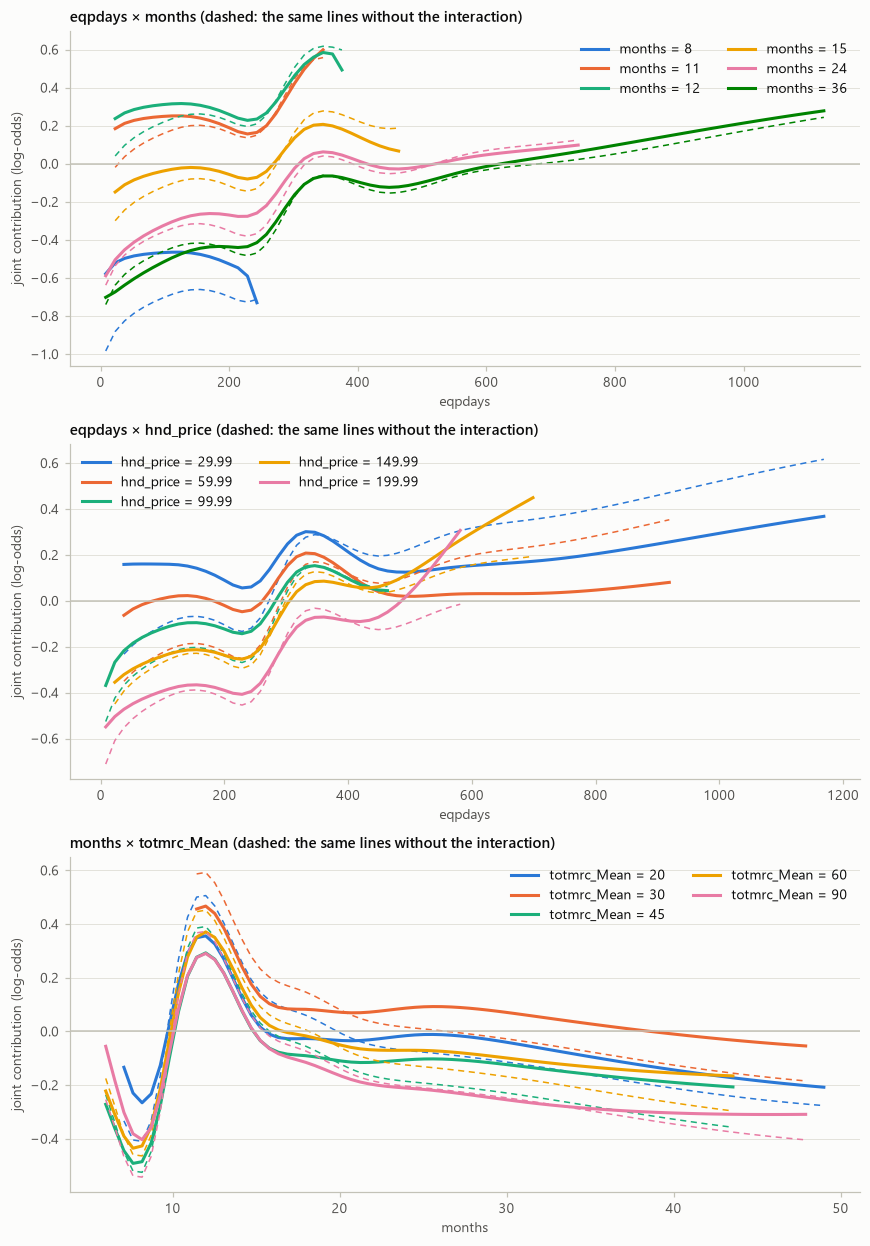

In [25]:
row = X.iloc[[0]]  # any customer: in an additive model the other columns do not change a pair's joint effect
panels = {}
for x, line in T:
    x_grid = np.linspace(*X[x].quantile([0.01, 0.99]), 80)
    panels[f"{x} × {line}"] = tuple(
        model.on_support(model.joint_effect(pipe, row, x, x_grid, line, g["tensor_lines"][line]), X, g["tensor_support"])
        for pipe in (final_t, final))
fig = plots.plot_joint(panels)

In [26]:
contrast = {}
for x, line in T:
    lo, hi = g["tensor_contrast"][x]
    diff = {name: model.on_support(model.joint_effect(pipe, row, x, [lo, hi], line, g["tensor_lines"][line]), X,
                                   g["tensor_support"]).diff(axis=1)[hi]
            for name, pipe in {"with surface": final_t, "additive GAM": final}.items()}
    contrast[f"{x} {lo} → {hi}, by {line}"] = pd.DataFrame(diff)
pd.concat(contrast).assign(odds_ratio_with_surface=lambda d: np.exp(d["with surface"]))

with surface  additive GAM  \
eqpdays 270 → 330, by months    8.0000             NaN           NaN   
                                11.0000         0.2986        0.2873   
                                12.0000         0.2447        0.2873   
                                15.0000         0.1983        0.2873   
                                24.0000         0.2224        0.2873   
                                36.0000         0.2392        0.2873   
eqpdays 270 → 330, by hnd_price 29.9900         0.1745        0.2873   
                                59.9900         0.1784        0.2873   
                                99.9900         0.2024        0.2873   
                                149.9900        0.2269        0.2873   
                                199.9900        0.2251        0.2873   
months 8 → 12, by totmrc_Mean   20.0000         0.6170        0.9222   
                                30.0000            NaN           NaN   
                                45.0000         0.7866        0.9222   
                                60.0000         0.8068        0.9222   
                                90.0000         0.6936        0.9222   

                                          odds_ratio_with_surface  
eqpdays 270 → 330, by months    8.0000                        NaN  
                                11.0000                    1.3480  
                                12.0000                    1.2772  
                                15.0000                    1.2193  
                                24.0000                    1.2491  
                                36.0000                    1.2703  
eqpdays 270 → 330, by hnd_price 29.9900                    1.1906  
                                59.9900                    1.1954  
                                99.9900                    1.2244  
                                149.9900                   1.2547  
                                199.9900                   1.2525  
months 8 → 12, by totmrc_Mean   20.0000                    1.8534  
                                30.0000                       NaN  
                                45.0000                    2.1959  
                                60.0000                    2.2407  
                                90.0000                    2.0009

In [27]:
# Observed churn rate per cell of the training set (cells under eda.min_bin_size customers left blank).
bins = {**s["bands"], **cfg["eda"]["grid_bins"]}
for x, line in T:
    grid = eda.churn_by_grid(train, line, bins[line], x, bins[x], TARGET, min_n=cfg["eda"]["min_bin_size"])
    display(grid["churn_rate"].unstack(x).rename_axis(f"churn rate: {line} (rows) by {x} (columns)", axis=0))

eqpdays,0,300,360,720
churn rate: months (rows) by eqpdays (columns),,,,
6,0.3198,0.5377,NaN,NaN
11,0.6092,0.6525,0.5904,NaN
13,0.4898,0.5742,0.5410,NaN
19,0.4105,0.5087,0.5467,0.5496
25,0.3633,0.4827,0.5206,0.5764


eqpdays,0,300,360,720
churn rate: hnd_price (rows) by eqpdays (columns),,,,
0,0.4988,0.6728,0.5793,0.5874
30,0.4447,0.6278,0.5179,0.5020
60,0.4386,0.6027,0.4974,0.5293
100,0.3637,0.6010,0.5521,0.5330
160,0.3428,0.5495,0.4849,NaN


months,6,11,13,19,25
churn rate: totmrc_Mean (rows) by months (columns),,,,,
-100,0.4447,0.6453,0.5581,0.5564,0.5281
20,0.4864,0.6371,0.5685,0.5708,0.5751
30,0.3643,0.6392,0.5142,0.5190,0.5252
40,0.2893,0.6443,0.5237,0.4833,0.4689
60,0.3116,0.6217,0.5058,0.4428,0.4055
75,0.3417,0.5770,0.5041,0.4197,0.4026
100,0.3901,0.5435,0.4870,0.3727,0.3500


**Takeaway:** **the interactions are real but small.** The three surfaces add +0.0024 ± 0.0003 ROC-AUC (paired, 8 SE) and −0.0016 log-loss in CV, and 0.681 against 0.679 on the hold-out. That closes 12% of the gap to XGBoost; the remaining 0.017 is spread over many smaller interactions, since the ranking falls off slowly after the top four. The main effects carry the story, and the surfaces refine it.
- **Handset age × tenure: the strongest pair is mostly a constraint, not an interaction.**
  - No customer has a handset older than the account (0 in the training set after cleaning), so the pair lives on a triangle: at 8 months a handset is at most ~240 days old, at 11–12 months at most ~375.
  - For a customer still on the handset from signup, the 300-day step and the 11–13-month peak arrive together. That shared timing likely explains much of XGBoost's interaction value (a hypothesis, not measured here).
  - Inside the triangle the lines stay nearly parallel. The 270 → 330-day step is +0.30 log-odds at 11 months, +0.24 at 12 and +0.20 to +0.24 from 15 to 36 months; the additive model has +0.29 everywhere. **The two effects are separate and roughly add up**, as the EDA showed: churn is 61% at 11–12 months even with a handset under 300 days.
  - One correction: at 8 months a new handset protects less than the additive model says (−0.5 instead of −0.85 log-odds at 50 days). Two protective signals that describe the same new customer were counted twice.
- **Handset age × handset price: past ~500 days, the price splits the curve.**
  - Up to the 300-day step the lines are nearly parallel. The step grows slightly with the price: +0.17 for $30 handsets and +0.23 for $150–200 (odds ×1.19 → ×1.25). Observed churn agrees: from under 300 to 300–360 days it rises 16–18 points for handsets under $100 and 21–24 points for $100 or more.
  - Past ~500 days an expensive handset keeps raising the risk ($150: from +0.1 at 500 days to +0.45 at 700), while a cheap one stops adding: the $30 and $60 lines stay well below their additive versions.
  - Reading: owners of premium handsets want the next premium handset. An 18-month-old premium handset is an upgrade opportunity; a cheap one is not. The high-price lines past 500 days rest on fewer customers (they end at 580–700 days).
- **Tenure × plan fee: the peak is there on every plan, but what follows it differs.**
  - The 11–12-month peak has nearly the same shape on every fee: months 8 → 12 adds +0.62 on $20, +0.79 on $45, +0.81 on $60 and +0.69 on $90 (odds ×1.9–2.2; additive +0.92).
  - After the peak, customers on $30 plans stay at raised risk (+0.08 from 15 to 30 months, where the additive line falls to −0.1), while $90 customers become the safest (−0.3). Observed churn agrees on the gap that opens: at 25+ months it is 53–58% on $20–40 plans and 35–41% on $60 or more.
  - Customers on exactly $30 are almost all past 11 months (1st percentile of tenure: 11 months, across 4,490 customers). It looks like a plan no longer sold to new customers, so its line starts at month 11 and its contrast is blank.
- **For retention**:
  - the handset offer before day 300 stands for everyone; after ~18 months it should target owners of premium handsets;
  - the renewal contact at month 9–10 stands on every plan;
  - after the peak, keep watching customers on $20–40 plans, who do not settle the way those on $60+ plans do.

## Conclusions

**Results** (5-fold CV on the training set; hold-out scored once, for the report)
1. The GAM uses cubic splines on every numeric, 10 knots at quantiles and a ridge penalty C = 3·10⁻⁴, both chosen by the one-SE rule. It reaches **ROC-AUC 0.677 in CV and 0.679 on the hold-out**, between the logistic regression (0.642) and XGBoost (0.696). On the hold-out: PR-AUC 0.663, log-loss 0.642, precision, recall and F1 0.625 at 0.5; 76% of the riskiest 10% churn (XGBoost 79%).
2. **About two thirds of XGBoost's gain over the linear model comes from shapes** (64% of the ROC-AUC gain, 57% of the log-loss gain). The remaining third comes from interactions, which only the trees capture.
3. **XGBoost stays the pipeline model**: it is 0.020 ROC-AUC ahead, about 28 paired SEs. The decision was taken on CV, before the hold-out.
4. The engineered ratios help the GAM (+0.0018 ROC-AUC, 4 SE), unlike the other two models: an additive model cannot draw a curve of a ratio from its two parts.
5. The curves and the ranking are stable across 5 refits (rank correlation 0.98; curves within 6–16% of each variable's importance).
6. **Three interaction surfaces** (handset age × tenure, handset age × handset price, tenure × plan fee, chosen from XGBoost's SHAP interactions on a training fold) add +0.0024 ROC-AUC (8 paired SEs; hold-out 0.681). They close 12% of the gap to XGBoost; the rest is many small interactions.

**What the GAM confirms** (association, not causation)
1. **The same top 5 drivers as XGBoost**, with importance rankings correlated 0.92: handset age, tenure, usage against own history, usage trend, extra subscribers.
2. **The same shapes**, now as exact, global curves:
   - a tenure peak at 11–12 months (odds ×2.5 against months 8–9);
   - risk rising steadily as usage falls below ~85% of the customer's own average;
   - a V in the usage trend;
   - entry-level plans of $20–40 and cheap handsets riskier.
3. **Handset age changes between 250 and 330 days** in both models. XGBoost places a sharp step at 300; the GAM smooths it. The "act before day 300" recommendation holds.
4. **New from the GAM's curves: dropped calls work as a threshold.** The contribution climbs over the first ~5 dropped calls a month, then stays flat. The network-quality follow-up should trigger on a few drops, not wait for many.
5. **The interactions refine the drivers; they add no new ones.**
   - Handset age and tenure are separate effects that coincide for customers on their original handset, since no handset is older than the account.
   - Old premium handsets keep raising the risk; old cheap ones do not.
   - After the tenure peak, customers on $20–40 plans stay at risk while those on $60+ settle.

**For the presentation**
- The GAM curves are the cleanest picture of each driver for a non-technical audience: one line per variable, exact, with its stability shown. XGBoost's dependence plots show the same shapes blurred by interactions. **Use the GAM curves to explain the drivers and XGBoost to score customers.**
- If a fully auditable model were required (a regulator, a scorecard), the GAM would cost 0.017 ROC-AUC on the hold-out and about 4 points of precision in the top 10%.

**Limits**
- Ridge on the spline weights, not a curvature penalty with one smoothing parameter per variable (`mgcv`/`pygam`). One C serves every curve, so sharp features are smoothed (the handset step, month 10) and the edges extrapolate a trend where customers are few.
- Near-duplicate usage variables share and offset credit (`avgmou`, `avgqty`): read the usage family as one driver.
- An interaction surface is only estimated where customers are. Each variable can be inside its own range while the pair is not, so the surfaces are drawn only on each line's observed range.
- Probabilities, precision and PR-AUC are on the ~50% sample. Zero usage may be measured after the decision to leave (the open observation-date question).